In [62]:
import os
import numpy as np
import pandas as pd
from collections import defaultdict
from tqdm import trange, tqdm

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances
import pickle

from utils import *

from sklearn.metrics import confusion_matrix
import seaborn as sns

In [63]:
df_flopp = pd.read_csv('processed_data/df_flopp_new.csv')
del df_flopp['Unnamed: 0'] 

df_flopp.insert(2, "data_source", 'flopp')

df_flopp_e = pd.read_csv('processed_data/df_flopp_e_new.csv')
del df_flopp_e['Unnamed: 0'] 

df_flopp_e.insert(2, "data_source", 'flopp_e')

flopp_flopp_e_pivot_new = pd.concat([df_flopp, df_flopp_e], axis=0).reset_index(drop=True)

flopp_flopp_e_pivot = pd.read_csv('processed_data/flopp_flopp_e_pivot.csv')
del flopp_flopp_e_pivot['Unnamed: 0'] 
flopp_flopp_e_pivot.columns = list(flopp_flopp_e_pivot.columns[:3]) + list(np.float64(flopp_flopp_e_pivot.columns[3:]))


check = flopp_flopp_e_pivot_new.iloc[:,:2].merge(flopp_flopp_e_pivot.iloc[:,:2], on ="file_name", how='left')
check.loc[pd.isna(check['polymer_y']),'polymer_y'] = 'Rubber'
#np.where(~(check['polymer_x'] == check['polymer_y']))[0]
#check.iloc[np.where(~(check['polymer_x'] == check['polymer_y']))[0],:]
flopp_flopp_e_pivot_new.loc[~(check['polymer_x'] == check['polymer_y']),'polymer'] = check.loc[~(check['polymer_x'] == check['polymer_y']),'polymer_y']
flopp_flopp_e_pivot_new.columns = list(flopp_flopp_e_pivot_new.columns[:3]) + list(np.float64(flopp_flopp_e_pivot_new.columns[3:]))


flopp_flopp_e_pivot_new.iloc[:,3:] = (1-np.log10(flopp_flopp_e_pivot_new.iloc[:,3:]/100))


#flopp_flopp_e_pivot_new


In [99]:
spectra_data_ir = pd.read_csv('passive_data/data_ir_passive_data.csv')
del spectra_data_ir['Unnamed: 0']
spectra_data_ir.columns = list(np.float64(spectra_data_ir.columns[:-4])) + list(spectra_data_ir.columns[-4:])
#spectra_data_ir

wn_gl = np.array(spectra_data_ir.columns[:-4])

idx_gl = list(np.logical_or(np.logical_and(wn_gl > 980, wn_gl < 1800),
                       np.logical_and(wn_gl > 2720, wn_gl < 2970) #2993.64990234375-10
                      ) ) + [False]*4


wn_fl = np.array(flopp_flopp_e_pivot_new.columns[3:])

idx_fl = [False]*3 + list(np.logical_or(np.logical_and(wn_fl > 980, wn_fl < 1800),
                            np.logical_and(wn_fl > 2720, wn_fl < 2970) #2993.64990234375-10
                            ))
idx_fl[np.where(idx_fl)[0][-1]] = False

x_train_ir = flopp_flopp_e_pivot_new.iloc[:,idx_fl].to_numpy()
x_train_ir = norm_spect_pivot(x_train_ir, norm_type='SNV') #MINMAX
#x_train_ir = -x_train_ir
x_train_ir_diff = np.diff(x_train_ir)
x_train_ir_diff = norm_spect_pivot(x_train_ir_diff, norm_type='SNV')
y_train_ir = flopp_flopp_e_pivot_new.iloc[:,1]


x_test_ir = spectra_data_ir.loc[:,idx_gl].to_numpy()
x_test_ir = norm_spect_pivot(x_test_ir, norm_type='SNV') #MINMAX
x_test_ir_diff = np.diff(x_test_ir)
x_train_ir_diff = norm_spect_pivot(x_test_ir_diff, norm_type='SNV')


In [65]:
spectra_data_ir.query('background != "background"').shape

(2547, 558)

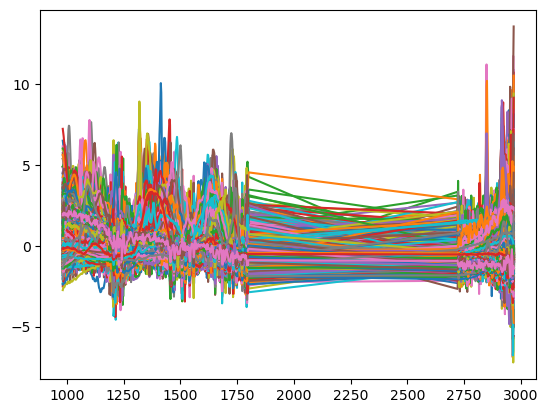

In [66]:
_ = plt.plot(spectra_data_ir.query('background != "background"').loc[:,idx_gl].T)

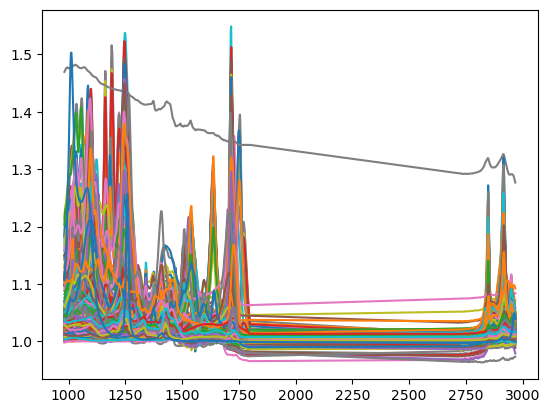

In [46]:
_ = plt.plot(flopp_flopp_e_pivot_new.loc[:,idx_fl].T)

In [104]:
pred_ = corr_matching(x_train_ir, y_train_ir, 
                      x_test_ir, r_min=0)
pred_polymers = pred_[0]
pred_hqi = pred_[1]
pred_df = pd.DataFrame(pred_polymers)
pred_df.columns = ['polymer_flopp']
pred_df['hqi_flopp'] = pred_hqi
pred_df = pred_df.reset_index(drop=True) 
pred_df['background_mean'] = spectra_data_ir['background']
matches_mean = pred_df.reset_index().query('hqi_flopp>.7').query('background_mean!="background"').groupby('polymer_flopp').count()#['hqi_flopp']
matches_mean

matches_mean_list = []
for th in np.linspace(.7,.9,10):
    matches_mean = pred_df.reset_index().query('hqi_flopp> @th').query('background_mean!="background"').groupby('polymer_flopp').count()['hqi_flopp']
    matches_mean_list.append(matches_mean)


matches_mean = pd.concat(matches_mean_list, axis=1)
matches_mean.columns = np.round(100*np.linspace(.7,.9,10),2)
matches_mean[np.isnan(matches_mean)] = 0
matches_mean.to_csv('passive_data/matches_res_mean_flopp_data.csv')
matches_mean

,70.00,72.22,74.44,76.67,78.89,81.11,83.33,85.56,87.78,90.00
polymer_flopp,,,,,,,,,,
Acrylic,1,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
Acrylonitrile Butadiene Styrene,9,9.0,7.0,6.0,5.0,4.0,3.0,1.0,1.0,0.0
Cellulose Acetate,2,2.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0
Cotton,119,117.0,116.0,114.0,111.0,108.0,100.0,93.0,83.0,72.0
Ethylene Acrylic Acid,1,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Polyamide,22,9.0,9.0,7.0,4.0,2.0,0.0,0.0,0.0,0.0
Polycarbonate,2,2.0,2.0,2.0,1.0,1.0,0.0,0.0,0.0,0.0
Polyethylene,53,51.0,49.0,49.0,48.0,46.0,43.0,36.0,32.0,23.0
Polyethylene Adipate,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [68]:
spectra_data_ir_res = spectra_data_ir.copy()
spectra_data_ir_res['polymer_flopp'] = pred_df['polymer_flopp']
spectra_data_ir_res['hqi_flopp'] = pred_df['hqi_flopp']
spectra_data_ir_res

,981.7028198242188,983.6317749023438,985.560791015625,987.4898071289062,989.4188232421875,991.3477783203125,993.2767944335938,995.205810546875,997.1348266601562,999.0637817382812,...,2962.785888671875,2964.71484375,2966.643798828125,2968.57275390625,map_x,map_y,id,background,polymer_flopp,hqi_flopp
0,1.734127,2.419397,-0.399766,-0.750546,0.913183,1.100276,-0.134475,-0.985368,-0.951970,0.834969,...,1.348981,-2.718058,-2.201744,1.236354,19395.199219,2398.699951,FHS_passive_July2024_D6_20240813_1,background,Polyethylene,0.132510
1,0.091801,-1.828973,0.008286,0.387269,-0.509035,0.612197,0.154604,-1.152029,-0.440574,-0.526350,...,-2.998919,1.524326,3.464395,2.477008,19384.699219,2399.100098,FHS_passive_July2024_D6_20240813_2,background,Polyethylene Vinyl Acetate,0.177957
2,-0.075321,-0.260037,0.363896,-0.511174,-1.167597,-0.814324,-0.546396,-0.199241,-0.720920,-0.422421,...,-2.268726,-5.138190,-6.916821,-7.919211,19409.099609,2405.399902,FHS_passive_July2024_D6_20240813_3,background,Polyethylene,0.226736
3,-0.651419,-0.267902,-0.174596,-0.647592,-0.307889,-0.670411,-0.414515,-0.084047,-0.744710,-1.285505,...,-4.129785,-3.146640,0.086870,3.337598,19372.000000,2407.199951,FHS_passive_July2024_D6_20240813_4,background,Polypropylene,0.212510
4,1.737391,2.278559,1.263099,-0.660179,-0.606585,0.049145,-0.122640,0.073713,0.342571,-0.002320,...,3.388266,3.461777,5.291844,4.058921,19411.849609,2410.850098,FHS_passive_July2024_D6_20240813_5,background,Polycarbonate,0.109361
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4363,0.956464,1.418004,2.014006,1.909727,2.217237,2.613354,2.636785,2.509610,2.364499,2.146140,...,-1.024237,-1.342570,-1.045898,0.010922,7783.100098,-485.600006,IAO_passive_June2024_G7_20240801_39,no_background,Rubber,0.943897
4364,-0.183061,-0.095919,-0.119556,-0.174708,-0.151427,-0.145177,-0.146811,-0.114293,-0.098024,-0.112260,...,-0.820057,-0.773873,-0.746549,-0.828798,7778.299805,-487.200012,IAO_passive_June2024_G7_20240801_40,no_background,Polystyrene,0.696300
4365,1.963018,1.809682,1.968297,1.946081,1.803461,1.980056,2.149049,2.324492,2.393598,2.233794,...,-2.019187,-1.398904,-1.230737,-0.983616,7740.350098,-478.950012,IAO_passive_June2024_G7_20240801_41,no_background,Rubber,0.935549
4366,1.757011,2.201591,2.704748,2.676028,2.120502,1.967140,1.924711,1.644775,1.611892,1.948868,...,-1.654030,-1.847609,-0.961392,-0.633345,7828.049805,-470.100006,IAO_passive_June2024_G7_20240801_42,no_background,Rubber,0.921852


In [112]:
flopp_norm = pd.DataFrame(x_train_ir)
flopp_norm.columns = wn_fl[idx_fl[:-3]]
flopp_norm['polymer'] = y_train_ir
flopp_norm.to_csv('passive_data/flopp_normal.csv')

Acrylic 1


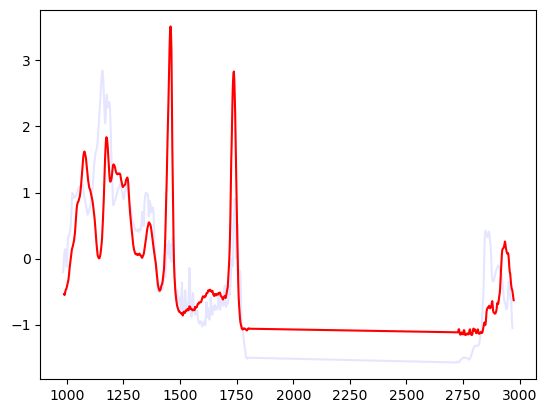

Acrylonitrile Butadiene Styrene 9


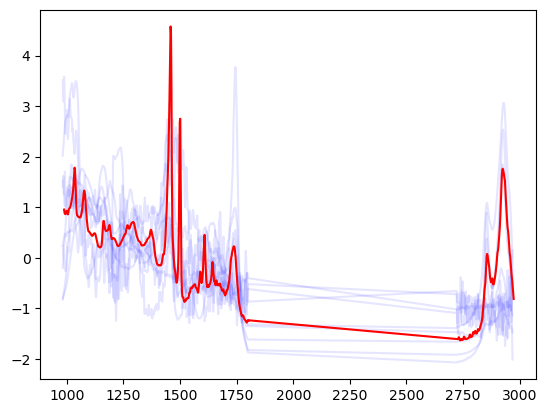

Cellulose Acetate 2


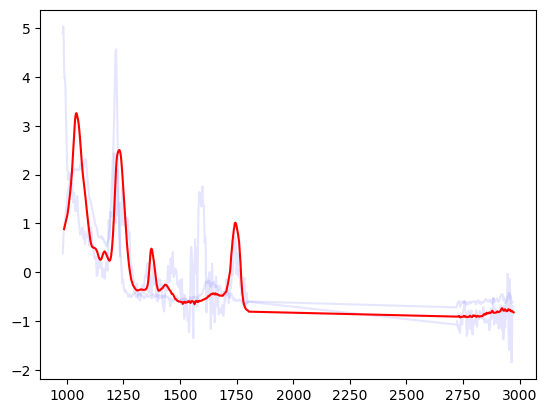

Cotton 131


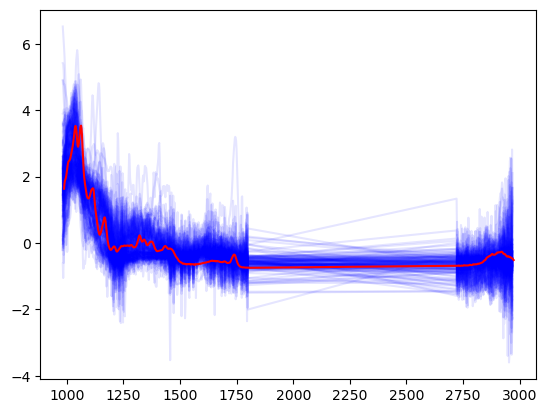

Ethylene Acrylic Acid 1


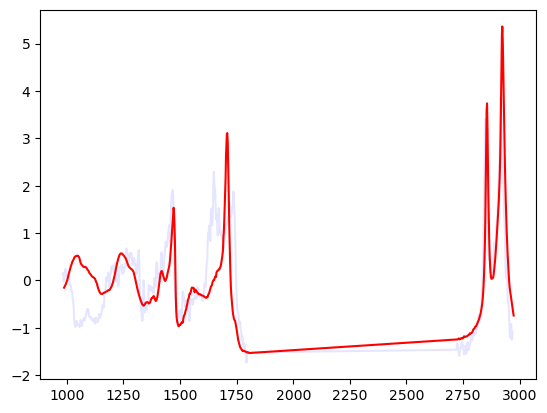

Polyamide 22


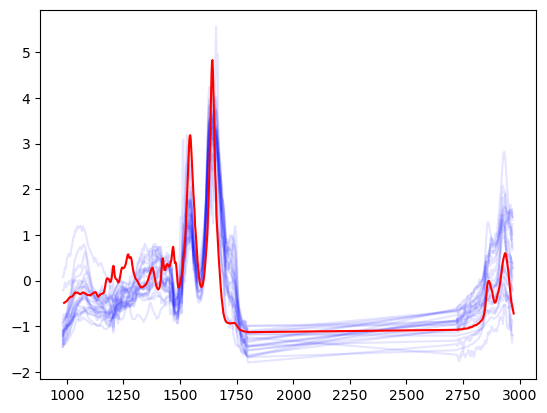

Polycarbonate 2


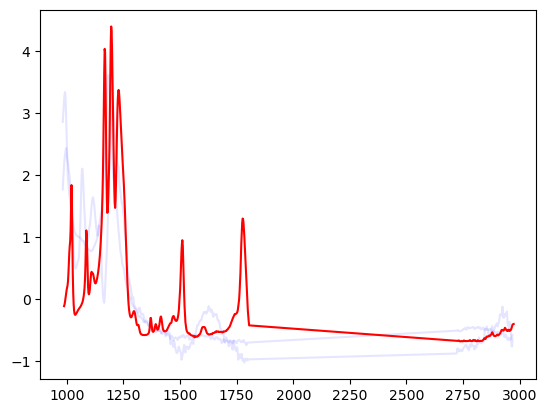

Polyethylene 61


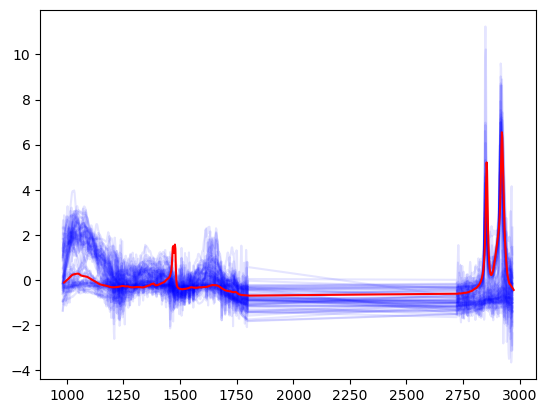

Polyethylene Adipate 1


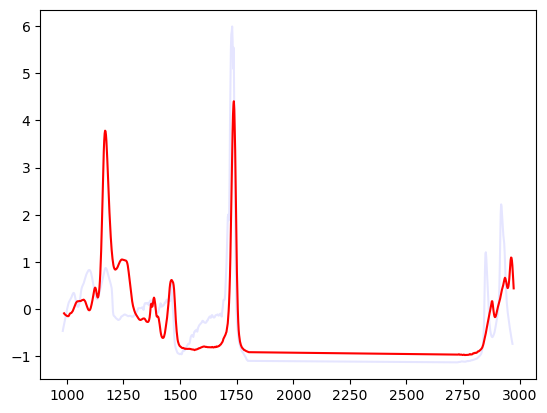

Polyethylene Terephthalate 1


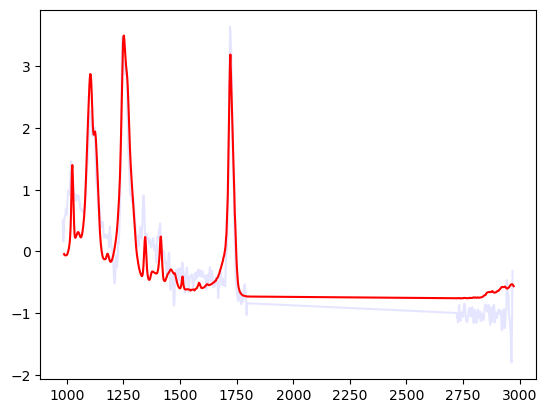

Polyethylene Vinyl Acetate 2


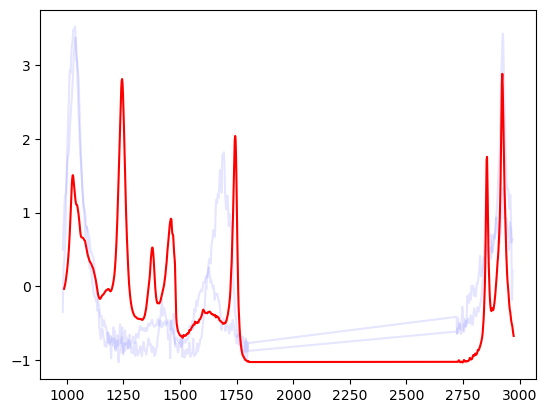

Polymethyl Methacrylate 3


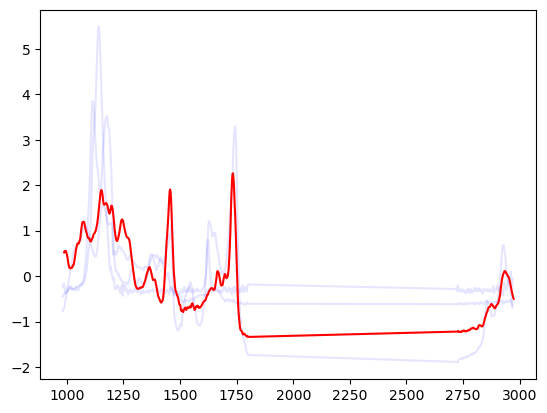

Polypropylene 99


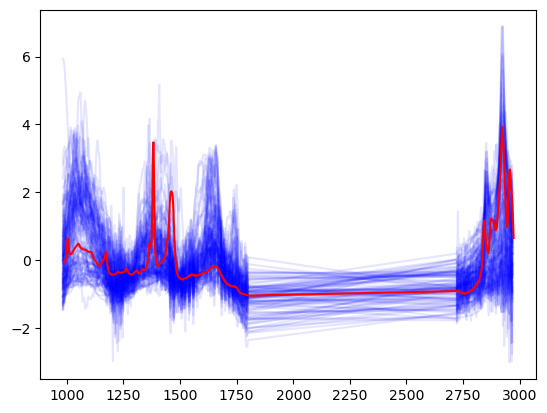

Polystyrene 376


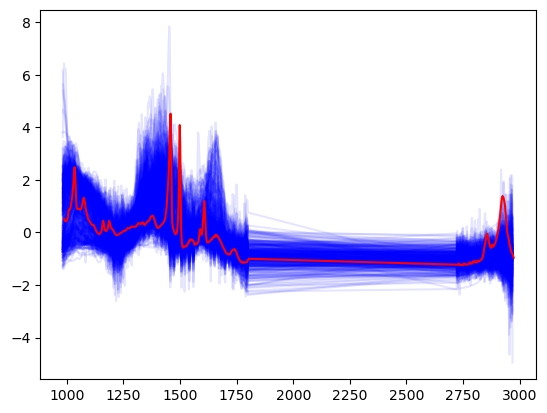

Polyurethane 25


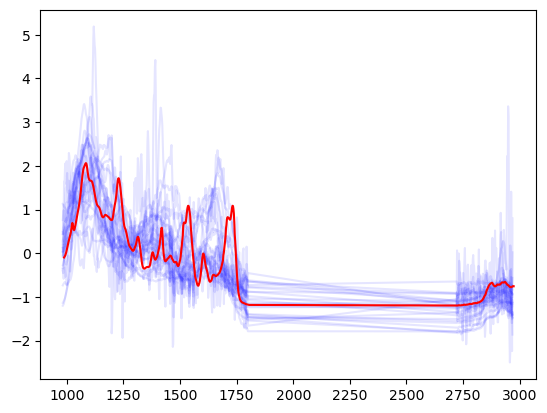

Polyvinyl Chloride 10


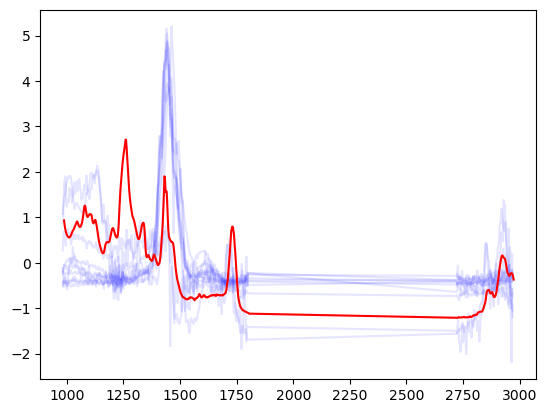

Rubber 1237


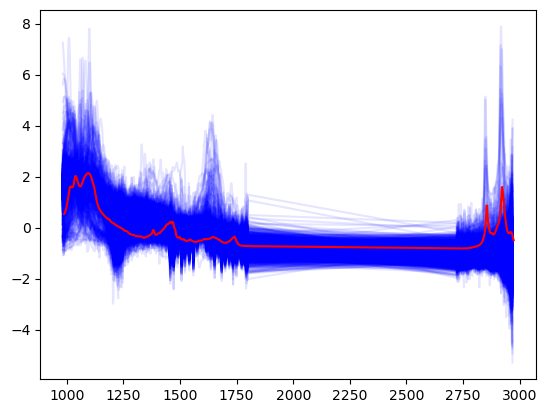

In [71]:
for i in range(matches_mean.shape[0]):
    poly = matches_mean.index[i]
    df_poly = spectra_data_ir_res.query('polymer_flopp == @poly and hqi_flopp > 0.70')
    print(poly, df_poly.shape[0])
    _ = plt.plot(df_poly.iloc[:,:-6].T, c='b', alpha=.1, label='passive_data')
    _ = plt.plot(wn_fl[idx_fl[:-3]], 
                 x_train_ir[y_train_ir == poly].mean(0), c='r', label='flopp')
    _ = plt.show()

In [113]:
rebecca_data_ir = pd.read_csv('gloves_contamination/data_ir_rebecca.csv')
del rebecca_data_ir['Unnamed: 0']
rebecca_data_ir.columns = list(np.float64(rebecca_data_ir.columns[:-3])) + list(rebecca_data_ir.columns[-3:])

wn_rb = np.array(rebecca_data_ir.columns[:-3])

idx_rb = list(np.logical_or(np.logical_and(wn_rb > 980, wn_rb < 1800),
                       np.logical_and(wn_rb > 2720, wn_rb < 2970) #2993.64990234375-10
                      ) ) + [False]*3


x_train_ir = rebecca_data_ir.iloc[:,idx_rb].to_numpy()
x_train_ir = norm_spect_pivot(x_train_ir, norm_type='SNV') #MINMAX
#x_train_ir = -x_train_ir
x_train_ir_diff = np.diff(x_train_ir)
x_train_ir_diff = norm_spect_pivot(x_train_ir_diff, norm_type='SNV')
y_train_ir = rebecca_data_ir.iloc[:,-1]


In [114]:
pred_reb = corr_matching(x_train_ir, y_train_ir, 
                      x_test_ir, r_min=0)
pred_reb_polymers = pred_reb[0]
pred_reb_hqi = pred_reb[1]
pred_reb_df = pd.DataFrame(pred_reb_polymers)
pred_reb_df.columns = ['polymer_reb_ir']
pred_reb_df['hqi_reb_ir'] = pred_reb_hqi
pred_reb_df = pred_reb_df.reset_index(drop=True) 
pred_reb_df['background_mean'] = spectra_data_ir['background']


matches_mean_list = []
for th in np.linspace(.7,.9,10):
    matches_mean = pred_reb_df.reset_index().query('hqi_reb_ir> @th').query('background_mean!="background"').groupby('polymer_reb_ir').count()['hqi_reb_ir']
    matches_mean_list.append(matches_mean)


matches_mean = pd.concat(matches_mean_list, axis=1)
matches_mean.columns = np.round(100*np.linspace(.7,.9,10),2)
matches_mean.to_csv('passive_data/matches_res_mean_rebecca_data.csv')
matches_mean

,70.00,72.22,74.44,76.67,78.89,81.11,83.33,85.56,87.78,90.00
polymer_reb_ir,,,,,,,,,,
NH2SO4,45,44,40,35,31,26,17,12,4,3
NaNO3,111,102,96,84,79,62,55,39,27,23
PE,19,18,18,17,16,15,15,14,13,11
PP,35,34,32,31,26,24,23,22,19,11
PSL,104,87,75,67,57,47,34,26,18,15
sucrose,1563,1525,1472,1265,609,364,301,241,193,122


In [116]:
reb_ir_norm = pd.DataFrame(x_train_ir)
reb_ir_norm.columns = wn_rb[idx_rb[:-3]]
reb_ir_norm['polymer'] = y_train_ir
reb_ir_norm.to_csv('passive_data/reb_ir_normal.csv')

In [106]:
spectra_data_ir_res = spectra_data_ir.copy()

spectra_data_ir_res['polymer_flopp'] = pred_df['polymer_flopp']
spectra_data_ir_res['hqi_flopp'] = pred_df['hqi_flopp']

spectra_data_ir_res['polymer_reb_ir'] = pred_reb_df['polymer_reb_ir']
spectra_data_ir_res['hqi_reb_ir'] = pred_reb_df['hqi_reb_ir']

spectra_data_ir_res.to_csv('passive_data/spectra_with_matches.csv')
spectra_data_ir_res

,981.7028198242188,983.6317749023438,985.560791015625,987.4898071289062,989.4188232421875,991.3477783203125,993.2767944335938,995.205810546875,997.1348266601562,999.0637817382812,...,2966.643798828125,2968.57275390625,map_x,map_y,id,background,polymer_flopp,hqi_flopp,polymer_reb_ir,hqi_reb_ir
0,1.734127,2.419397,-0.399766,-0.750546,0.913183,1.100276,-0.134475,-0.985368,-0.951970,0.834969,...,-2.201744,1.236354,19395.199219,2398.699951,FHS_passive_July2024_D6_20240813_1,background,Polyethylene,0.132510,PP,0.243776
1,0.091801,-1.828973,0.008286,0.387269,-0.509035,0.612197,0.154604,-1.152029,-0.440574,-0.526350,...,3.464395,2.477008,19384.699219,2399.100098,FHS_passive_July2024_D6_20240813_2,background,Polyethylene Vinyl Acetate,0.177957,NaNO3,0.282903
2,-0.075321,-0.260037,0.363896,-0.511174,-1.167597,-0.814324,-0.546396,-0.199241,-0.720920,-0.422421,...,-6.916821,-7.919211,19409.099609,2405.399902,FHS_passive_July2024_D6_20240813_3,background,Polyethylene,0.226736,PSL,0.564189
3,-0.651419,-0.267902,-0.174596,-0.647592,-0.307889,-0.670411,-0.414515,-0.084047,-0.744710,-1.285505,...,0.086870,3.337598,19372.000000,2407.199951,FHS_passive_July2024_D6_20240813_4,background,Polypropylene,0.212510,NaNO3,0.371484
4,1.737391,2.278559,1.263099,-0.660179,-0.606585,0.049145,-0.122640,0.073713,0.342571,-0.002320,...,5.291844,4.058921,19411.849609,2410.850098,FHS_passive_July2024_D6_20240813_5,background,Polycarbonate,0.109361,PP,0.332466
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4363,0.956464,1.418004,2.014006,1.909727,2.217237,2.613354,2.636785,2.509610,2.364499,2.146140,...,-1.045898,0.010922,7783.100098,-485.600006,IAO_passive_June2024_G7_20240801_39,no_background,Rubber,0.943897,sucrose,0.772961
4364,-0.183061,-0.095919,-0.119556,-0.174708,-0.151427,-0.145177,-0.146811,-0.114293,-0.098024,-0.112260,...,-0.746549,-0.828798,7778.299805,-487.200012,IAO_passive_June2024_G7_20240801_40,no_background,Polystyrene,0.696300,NaNO3,0.978374
4365,1.963018,1.809682,1.968297,1.946081,1.803461,1.980056,2.149049,2.324492,2.393598,2.233794,...,-1.230737,-0.983616,7740.350098,-478.950012,IAO_passive_June2024_G7_20240801_41,no_background,Rubber,0.935549,sucrose,0.767207
4366,1.757011,2.201591,2.704748,2.676028,2.120502,1.967140,1.924711,1.644775,1.611892,1.948868,...,-0.961392,-0.633345,7828.049805,-470.100006,IAO_passive_June2024_G7_20240801_42,no_background,Rubber,0.921852,sucrose,0.789811


NH2SO4 3


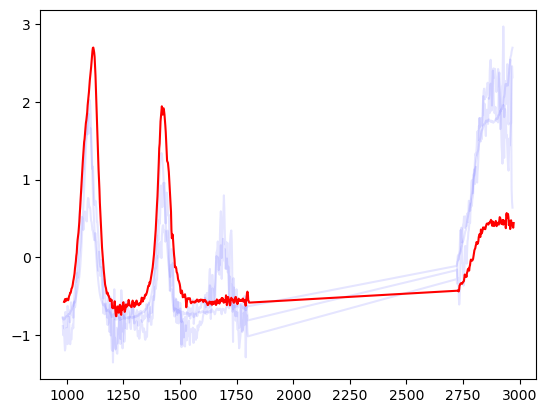

NaNO3 24


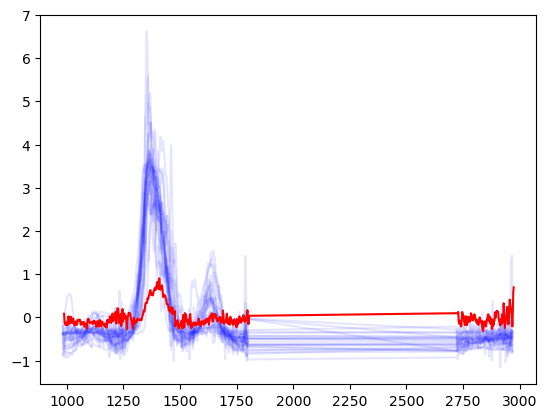

PE 13


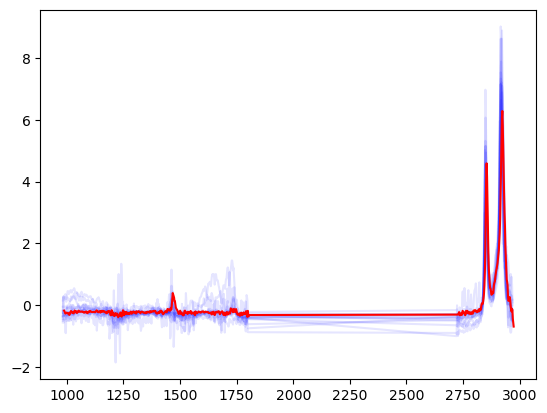

PP 11


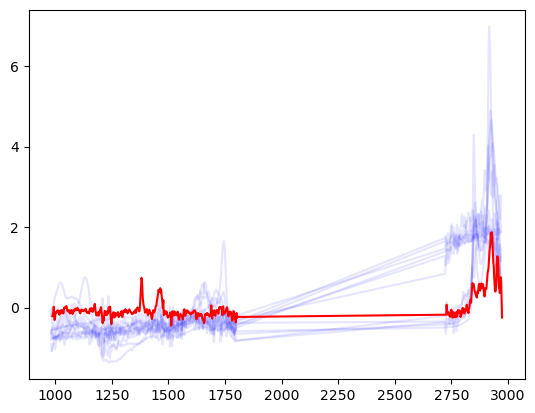

PSL 15


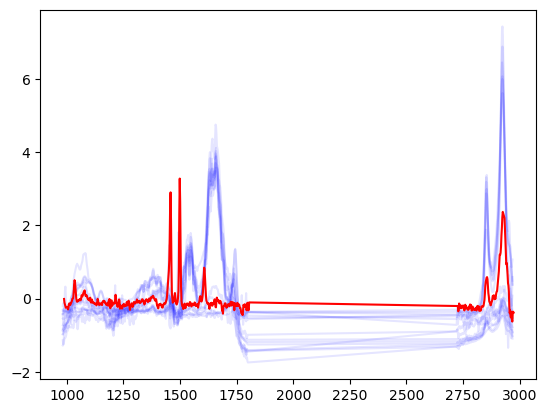

sucrose 124


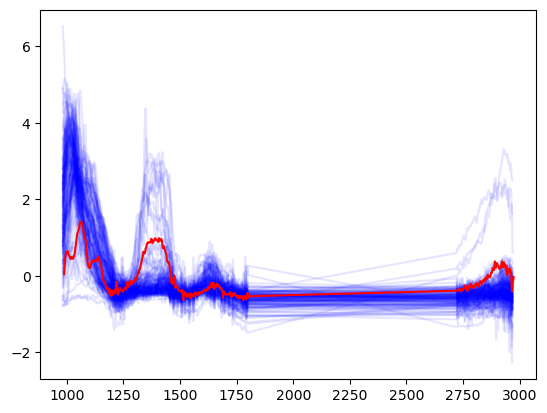

In [98]:
for i in range(matches_mean.shape[0]):
    poly = matches_mean.index[i]
    df_poly = spectra_data_ir_res.query('polymer_reb_ir == @poly and hqi_reb_ir > 0.90')
    print(poly, df_poly.shape[0])
    _ = plt.plot(df_poly.iloc[:,:-6].T, c='b', alpha=.1, label='passive_data')
    _ = plt.plot(wn_fl[idx_fl[:-3]], 
                 x_train_ir[y_train_ir == poly].mean(0), c='r', label='flopp')
    _ = plt.show()